# 阶段 1：数据探索与预处理

以订单商品明细的 `Quantity` 为预测目标。全量数据用于核对字段、缺失和时间范围；目标分布、数量关系与相关性分析使用训练集。

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'projects' / 'bakery-regression']
project_root = next((path.resolve() for path in candidates if (path / 'src' / 'preprocessing.py').is_file()), None)
if project_root is None:
    raise RuntimeError('请从工作区、项目或 notebooks 目录运行 Notebook')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_audit import audit_dataset, write_audit_report
from src.config import (
    BINARY_FEATURES, CATEGORICAL_FEATURES, EXCLUDED_FIELDS, FEATURE_COLUMNS,
    NUMERIC_FEATURES, TARGET_COLUMN, FIGURE_DIRECTORY,
)
from src.dataset import load_dataset, split_by_date
from src.preprocessing import build_preprocessor

data, cleaning_report = load_dataset()
splits = split_by_date(data)
report = audit_dataset(data, cleaning_report)
write_audit_report(report)
figure_dir = FIGURE_DIRECTORY
figure_dir.mkdir(parents=True, exist_ok=True)

## 数据质量与时间划分

`Festival` 的缺失保留为信息未指定；`Promotion_Type` 在未促销且类型缺失时填为 `No Promotion`。

In [2]:
overview = {
    '输入记录数': report['cleaning']['input_rows'],
    '跳过记录数': report['cleaning']['skipped_rows'],
    '记录数': report['rows'],
    '字段数': report['columns'],
    '起始日期': report['date_range']['start'],
    '结束日期': report['date_range']['end'],
    '有订单的天数': report['date_range']['days_with_orders'],
    '订单数': report['unique_counts']['orders'],
    '客户数': report['unique_counts']['customers'],
    '商品数': report['unique_counts']['products'],
    '门店数': report['unique_counts']['stores'],
    '完全重复记录': report['duplicate_rows'],
}
display(pd.Series(overview, name='数据概览').to_frame())
missing = pd.DataFrame.from_dict(report['missing_values'], orient='index')
display(missing.rename(columns={'count': '缺失数', 'percentage': '缺失率 (%)'}))
display(pd.DataFrame.from_dict(report['splits'], orient='index').rename(
    columns={'rows': '记录数', 'start': '开始日期', 'end': '结束日期'}
))
display(pd.Series(report['promotion_type_missing'], name='促销类型缺失数').to_frame())
display(pd.Series(report['calendar_feature_mismatches'], name='时间字段不一致数').to_frame())
display(pd.Series(report['cleaning']['skipped_by_reason'], name='跳过记录原因').to_frame())

,数据概览
输入记录数,19321
跳过记录数,0
记录数,19321
字段数,40
起始日期,2023-01-01
结束日期,2024-12-31
有订单的天数,731
订单数,6576
客户数,500
商品数,35


,缺失数,缺失率 (%)
Festival,16006,82.84
Promotion_Type,13826,71.56


,记录数,开始日期,结束日期
train,14340,2023-01-01,2024-06-30
validation,2533,2024-07-01,2024-09-30
test,2448,2024-10-01,2024-12-31


,促销类型缺失数
without_promotion,13826
with_promotion,0


,时间字段不一致数
Year,0
Month,0
Day,0
Day_of_Week,0
Weekend,0
Hour,0


,跳过记录原因
invalid_date,0
invalid_quantity,0
outside_periods,0
cross_split_order,0


## 字段角色与泄漏边界

预处理器按白名单读取输入。`Total_Bill`、`Profit` 和 `Units_Sold` 等结果字段排除在模型输入之外。

In [3]:
roles = {}
roles.update({column: ('输入', '数值') for column in NUMERIC_FEATURES})
roles.update({column: ('输入', '类别') for column in CATEGORICAL_FEATURES})
roles.update({column: ('输入', '二元 No/Yes') for column in BINARY_FEATURES})
roles.update({'Festival': ('输入', '节日缺失单独编码'), 'Promotion_Type': ('输入', '促销类型缺失单独编码')})
roles.update({column: ('排除', reason) for column, reason in EXCLUDED_FIELDS.items()})
roles[TARGET_COLUMN] = ('目标', '订单明细购买数量')
fields = pd.DataFrame([
    {'字段': column, '角色': roles.get(column, ('排除', '未列入输入白名单'))[0],
     '说明': roles.get(column, ('排除', '未列入输入白名单'))[1]}
    for column in data.columns
])
display(fields)

,字段,角色,说明
0,Order_ID,排除,订单标识符
1,Customer_ID,排除,客户标识符
2,Customer_Age,输入,数值
3,Customer_Gender,输入,类别
4,Customer_Segment,输入,类别
5,Loyalty_Member,输入,二元 No/Yes
6,Date,排除,用于时间划分，基础输入使用日期派生字段
7,Year,输入,数值
8,Month,输入,数值
9,Day,排除,基础候选字段未包含当月日期


## 训练集：目标分布与数量关系

数据集中 `Units_Sold` 与 `Quantity` 是不同字段。以下关系和账单、利润公式均在训练集核验。

,训练集 Quantity
mean,2.2204
median,2.0000
std,1.7777
min,1.0000
q75,3.0000
max,20.0000
skew,2.6053


,训练集数量关系
sold_greater,3779
equal,10561
sold_less,0


,公式不一致记录数
total_bill,0
profit,0


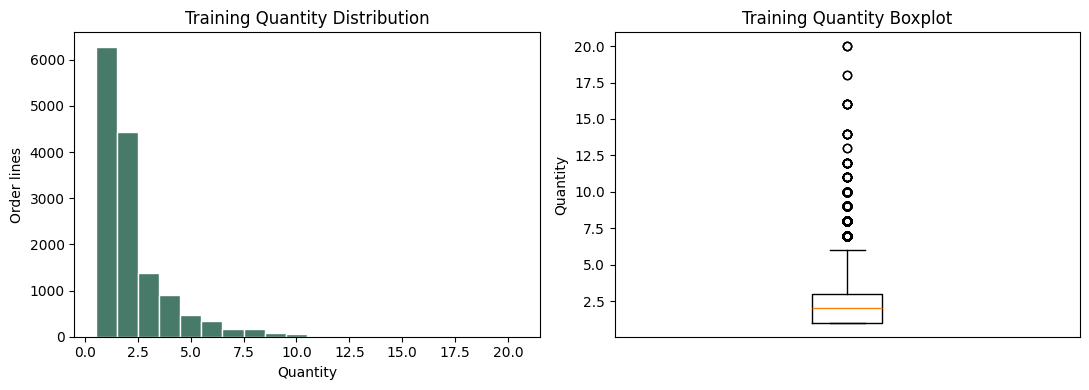

In [4]:
train = splits.train
display(pd.Series(report['training_quantity'], name='训练集 Quantity').to_frame())
display(pd.Series(report['training_quantity_vs_units_sold'], name='训练集数量关系').to_frame())
display(pd.Series(report['training_leakage_relationship_mismatches'], name='公式不一致记录数').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.arange(0.5, int(train[TARGET_COLUMN].max()) + 1.5, 1)
axes[0].hist(train[TARGET_COLUMN], bins=bins, color='#477a68', edgecolor='white')
axes[0].set(title='Training Quantity Distribution', xlabel='Quantity', ylabel='Order lines')
axes[1].boxplot(train[TARGET_COLUMN])
axes[1].set(title='Training Quantity Boxplot', ylabel='Quantity', xticks=[])
fig.tight_layout()
fig.savefig(figure_dir / '01_quantity_distribution.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

## 训练集：数值特征相关性

相关性反映线性关系，可为后续特征选择提供参考；非线性关系和类别特征将在模型实验中评估。

,Customer_Age,Temperature,Unit_Price,Discount_Percentage,Shelf_Life_Days,Year,Month,Hour,Quantity
Customer_Age,1.000,-0.015,-0.006,-0.014,0.027,-0.006,0.009,-0.001,-0.005
Temperature,-0.015,1.000,0.003,-0.005,-0.046,0.108,0.040,-0.017,-0.028
Unit_Price,-0.006,0.003,1.000,0.016,-0.055,-0.004,0.007,-0.007,-0.248
Discount_Percentage,-0.014,-0.005,0.016,1.000,-0.014,-0.037,0.042,0.020,0.053
Shelf_Life_Days,0.027,-0.046,-0.055,-0.014,1.000,-0.006,-0.006,0.009,-0.138
Year,-0.006,0.108,-0.004,-0.037,-0.006,1.000,-0.457,-0.020,-0.021
Month,0.009,0.040,0.007,0.042,-0.006,-0.457,1.000,0.005,0.026
Hour,-0.001,-0.017,-0.007,0.020,0.009,-0.020,0.005,1.000,0.011
Quantity,-0.005,-0.028,-0.248,0.053,-0.138,-0.021,0.026,0.011,1.000


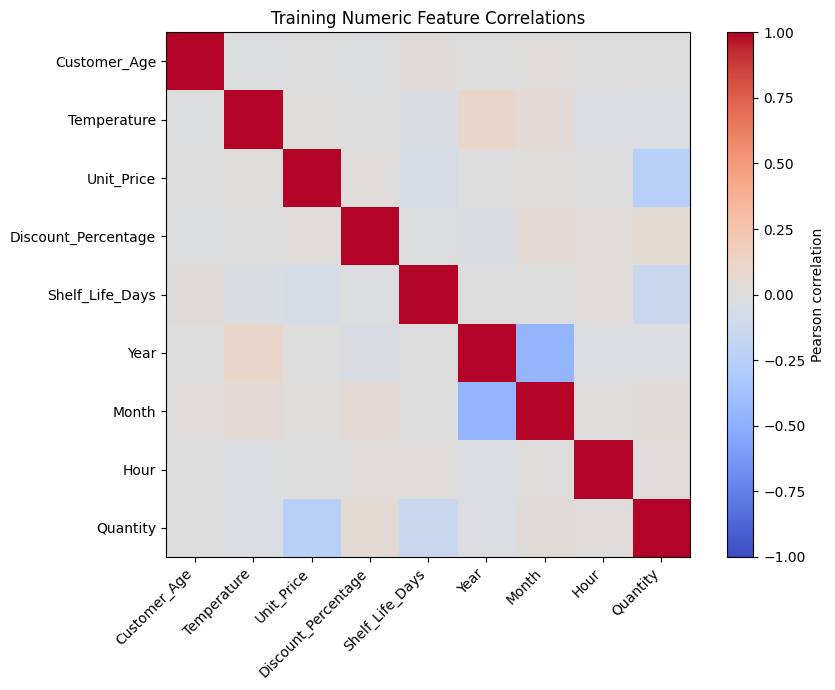

In [5]:
correlation = train[NUMERIC_FEATURES + [TARGET_COLUMN]].corr()
display(correlation.round(3))
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
ticks = np.arange(len(correlation.columns))
ax.set_xticks(ticks, correlation.columns, rotation=45, ha='right')
ax.set_yticks(ticks, correlation.index)
ax.set_title('Training Numeric Feature Correlations')
fig.colorbar(image, ax=ax, label='Pearson correlation')
fig.tight_layout()
fig.savefig(figure_dir / '02_training_correlations.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

## 训练集拟合与验证集转换

使用训练集拟合缺失值、标准化与类别编码，再转换验证集。模型训练时可将此预处理器作为 Scikit-learn Pipeline 的第一步。

In [6]:
preprocessor = build_preprocessor()
train_features = preprocessor.fit_transform(train[FEATURE_COLUMNS])
validation_features = preprocessor.transform(splits.validation[FEATURE_COLUMNS])
feature_names = preprocessor.get_feature_names_out()
assert train_features.shape[1] == validation_features.shape[1] == len(feature_names)
display(pd.DataFrame([
    {'数据集': 'train', '记录数': train_features.shape[0], '编码后特征数': train_features.shape[1]},
    {'数据集': 'validation', '记录数': validation_features.shape[0], '编码后特征数': validation_features.shape[1]},
]))
display(pd.DataFrame({'编码后特征示例': feature_names[:15]}))

,数据集,记录数,编码后特征数
0,train,14340,103
1,validation,2533,103


,编码后特征示例
0,numeric__Customer_Age
1,numeric__Temperature
2,numeric__Unit_Price
3,numeric__Discount_Percentage
4,numeric__Shelf_Life_Days
5,numeric__Year
6,numeric__Month
7,numeric__Hour
8,categorical__Product_Biscuit
9,categorical__Product_Black Forest Cake


阶段 1 交付了数据审计、时间划分与统一预处理。阶段 2 将以验证集比较基础回归模型；时间周期、交互和特征选择在阶段 3 开展。